# 03 - Baseline

**Objetivo:** tener una referencia simple contra la cual medir el feature engineering y los modelos posteriores.

**Enfoque:** LightGBM con variables crudas (sin feature engineering), entrenado en train y evaluado en validación. El tramo de **test no se toca** hasta el final del proyecto, para que la evaluación final sea honesta.

In [10]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import precision_recall_curve

from src.validation import add_day, temporal_split
from src.evaluate import evaluate, evaluate_by_segment

sns.set_theme(style="whitegrid")

## 1. Datos y división temporal

In [11]:
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))

# LightGBM necesita dtype 'category' para las variables categóricas
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in cat_cols:
    df[c] = df[c].astype("category")
print(f"{len(cat_cols)} columnas categóricas")

train, valid, test = temporal_split(df)
print(len(train), len(valid), len(test))

31 columnas categóricas
410601 85303 94636


## 2. Selección de variables
Se excluyen:
- `TransactionID`: identificador, no tiene significado predictivo.
- `TransactionDT` y `day`: el tiempo absoluto no se extrapola al futuro (los tramos de valid/test tienen valores fuera del rango visto en train).
- `isFraud`: el target.

In [12]:
DROP = ["TransactionID", "TransactionDT", "day", "isFraud"]
features = [c for c in df.columns if c not in DROP]

X_train, y_train = train[features], train["isFraud"]
X_valid, y_valid = valid[features], valid["isFraud"]
len(features)

432

## 3. Modelo
Parámetros razonables y sin tuning. Sin ajuste por desbalance todavía: es el punto de partida. Early stopping sobre validación.

In [13]:
params = dict(
    objective="binary",
    learning_rate=0.05,
    n_estimators=2000,
    num_leaves=64,
    colsample_bytree=0.5,
    subsample=0.8,
    subsample_freq=1,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

model = lgb.LGBMClassifier(**params)
model.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)
print("Mejor iteración:", model.best_iteration_)

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.906486	valid_0's binary_logloss: 0.0898731
[200]	valid_0's auc: 0.91775	valid_0's binary_logloss: 0.0856414
[300]	valid_0's auc: 0.920376	valid_0's binary_logloss: 0.0843805
[400]	valid_0's auc: 0.923574	valid_0's binary_logloss: 0.0833867
[500]	valid_0's auc: 0.92428	valid_0's binary_logloss: 0.0831447
[600]	valid_0's auc: 0.925021	valid_0's binary_logloss: 0.0830404
Early stopping, best iteration is:
[559]	valid_0's auc: 0.925052	valid_0's binary_logloss: 0.082948
Mejor iteración: 559


## 4. Evaluación en validación

In [14]:
p_valid = model.predict_proba(X_valid)[:, 1]
results = evaluate(y_valid, p_valid)
pd.Series(results).round(4)

auc_pr           0.6113
auc_roc          0.9251
tasa_base        0.0347
recall@prec50    0.6026
recall@prec80    0.4450
dtype: float64

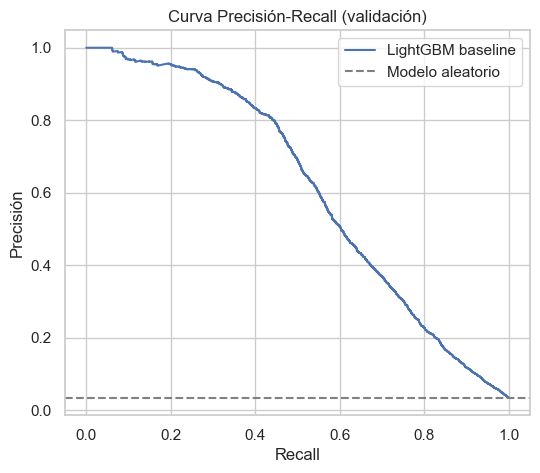

In [15]:
prec, rec, _ = precision_recall_curve(y_valid, p_valid)
plt.figure(figsize=(6, 5))
plt.plot(rec, prec, label="LightGBM baseline")
plt.axhline(y_valid.mean(), color="gray", linestyle="--", label="Modelo aleatorio")
plt.xlabel("Recall"); plt.ylabel("Precisión"); plt.title("Curva Precisión-Recall (validación)")
plt.legend(); plt.show()

## 5. Evaluación por segmento
Como se vio en la validación temporal, `ProductCD` y `has_identity` cambian de composición entre tramos. Verificamos que el modelo rinda de forma parecida en cada segmento.

In [16]:
evaluate_by_segment(valid, p_valid, "ProductCD")

,filas,fraudes,tasa_fraude_%,auc_pr,auc_roc
ProductCD,,,,,
C,8874,1123,12.6549,0.8071,0.9320
H,2270,135,5.9471,0.7158,0.9404
R,3245,161,4.9615,0.8660,0.9765
S,1347,86,6.3846,0.6719,0.9127
W,69567,1457,2.0944,0.3872,0.9006


In [17]:
evaluate_by_segment(valid, p_valid, "has_identity")

,filas,fraudes,tasa_fraude_%,auc_pr,auc_roc
has_identity,,,,,
0,70187,1496,2.1314,0.3915,0.9009
1,15116,1466,9.6983,0.8005,0.9426


## 6. Importancia de variables

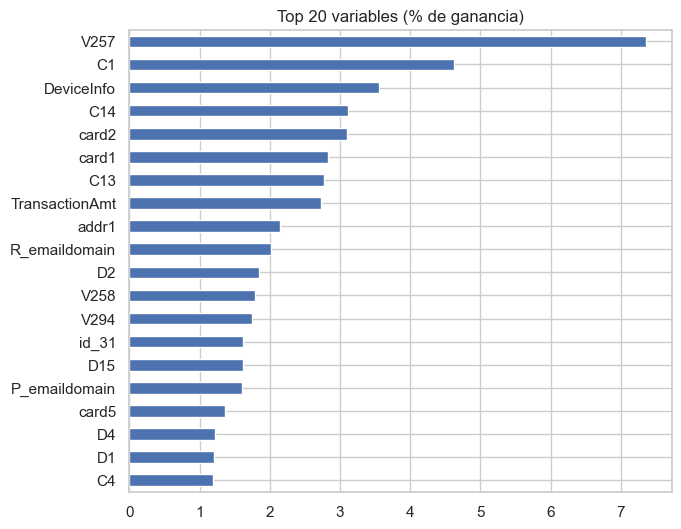

In [18]:
imp = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=features)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
imp.head(20).iloc[::-1].plot(kind="barh", figsize=(7, 6), title="Top 20 variables (% de ganancia)")
plt.show()

## 7. Conclusiones del baseline

**Resultados (validación temporal)**
- AUC-PR: 0,611 (≈17x la tasa base de 3,47%) | AUC-ROC: 0,925.
- Recall con precisión ≥50%: 60,3% | con precisión ≥80%: 44,5%.
- Mejor iteración: 559 (learning rate 0,05, sin ajuste por desbalance).

**Rendimiento por segmento**
- El AUC-ROC es alto y estable en todos los segmentos (0,90-0,98).
- El AUC-PR más bajo en `ProductCD = W` (0,39) y `has_identity = 0` (0,39) refleja su menor tasa de fraude (~2,1%), no un peor desempeño relativo: equivale a ~18x la tasa base del segmento.
- Estos dos segmentos concentran ~82% de las transacciones y son los más difíciles; es donde más se puede ganar.

**Variables más importantes**
- V257 (enmascarada), C1, C13, C14, card1, card2, DeviceInfo.
- Predominan variables que identifican o describen al cliente/dispositivo, lo que sugiere trabajar en un identificador aproximado de cliente y en agregaciones por cliente.

**Limitaciones**
- Early stopping sobre validación: la métrica es levemente optimista; el test se reserva para el resultado final.
- Variables enmascaradas (V*): limitan la interpretabilidad.

**Próximos pasos**
- Feature engineering centrado en cliente aproximado, frecuencias y comportamiento temporal.